#### Setup

In [1]:
#import all necessary extensions
import numpy as np, pandas as pd, scipy.sparse as sp, time
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt
import tracemalloc

In [2]:
#reading the file
filename = "data/raw/online_retail_II.xlsx"
sheets = pd.read_excel(filename, sheet_name=None)


#### Helper functions

In [3]:
#creating small helper function to print removed rows after each cleaning
cleaning_log = []

def log_removed_rows(rule, df_before_change, df_after_change):
      removed = len(df_before_change) - len(df_after_change)
      print(rule, "Rows removed:", removed, "| New data size:", len(df_after_change))
      cleaning_log.append({"rule": rule, "rows_removed": removed,
                           "rows_left": len(df_after_change)})
      return df_after_change

### Data Exploration

#### DE1

In [4]:
#uniting two sheets into one dataframe
df = pd.concat(sheets.values(), ignore_index = True)

In [5]:
#looking at first five rows of the file
df.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


In [6]:
#length of the data frame (must be > million)
len(df)

1067371

In [7]:
#checking types and names of columns
df.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

Customer ID is type float64, but it must be a whole number. Potentially happens because missing customer IDs are Nan which is float, therefore, the whole column must be float. We will fix it after handling missing values.

In [8]:
#how many missing values we have per column
print(df.isna().sum())

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [9]:
#want to see percentage of missing values for every column
print(df.isna().mean()*100)

Invoice         0.000000
StockCode       0.000000
Description     0.410541
Quantity        0.000000
InvoiceDate     0.000000
Price           0.000000
Customer ID    22.766873
Country         0.000000
dtype: float64


The dataset looks good for missing values besides Description and CustomerID field. Customer ID misses are 22.8% of the whole dataset - potentially all of it can be dropped. Then possibly Description will have less missing values as well.

#### DE2

First, we will deal with cancellations. By project rules the invoices that start from C are cancelled and should not be in our data.

In [10]:
print("DF before removing cancellations: ", len(df))

df_no_cancellations = df[~df["Invoice"].astype(str).str.startswith('C')]

df = log_removed_rows("Cancellations.", df, df_no_cancellations)

DF before removing cancellations:  1067371
Cancellations. Rows removed: 19494 | New data size: 1047877



Non-positive values for quantity and price will be removed because they are returns, adjustments or free items rather than real purchases, so keeping them would distort what customers actually bought.

In [11]:
#check for non-positive quantity or price
df[["Quantity", "Price"]].le(0).any()

Quantity    True
Price       True
dtype: bool

In [12]:
df_cleaned = df[(df['Price'] > 0) & (df['Quantity'] > 0)]

df = log_removed_rows("Non-positive price or quantity.", df, df_cleaned)

Non-positive price or quantity. Rows removed: 6207 | New data size: 1041670


Next we will clean our dataframe from non-product codes. We are going to leave only the ones that follow a format of 5 digits with optional letter. All others are non-product codes and should not be in our dataframe.

In [13]:
#defining the regex pattern (5 digits, followed by optional letters)
pattern = r'^\d{5}[a-zA-Z]*$'

#filtering the DataFrame to keep only matching rows
df_filtered = df[df['StockCode'].astype(str).str.match(pattern, na=False)]

df = log_removed_rows("Product codes left only.", df, df_filtered)

Product codes left only. Rows removed: 4794 | New data size: 1036876


Next, we will be dropping rows with empty CustomerID's. Every row has to go into a customer x product matrix and a row without CustomerID has no customer to belong to, therefore, useless for our purpose.

In [14]:
df_cleaned = df[df['Customer ID'].notna()]

df = log_removed_rows("Left non-empty CustomerID rows.", df, df_cleaned)

df['Customer ID'] = df['Customer ID'].astype(int) # bring ID's back to whole numbers

Left non-empty CustomerID rows. Rows removed: 234244 | New data size: 802632


In [15]:
pd.DataFrame(cleaning_log)

,rule,rows_removed,rows_left
0,Cancellations.,19494,1047877
1,Non-positive price or quantity.,6207,1041670
2,Product codes left only.,4794,1036876
3,Left non-empty CustomerID rows.,234244,802632


#### DE3

In [16]:
latest_date = df["InvoiceDate"].max()
cutoff_date = latest_date - pd.DateOffset(months=2)
print(cutoff_date, " - ", latest_date)

2011-10-09 12:50:00  -  2011-12-09 12:50:00


In [17]:
train = df[df["InvoiceDate"] < cutoff_date]
test  = df[df["InvoiceDate"] >= cutoff_date]

print("Train rows:", len(train), "| Test rows:", len(test))
print("Train:", train["InvoiceDate"].min(), "to", train["InvoiceDate"].max())
print("Test: ", test["InvoiceDate"].min(), "to", test["InvoiceDate"].max())

Train rows: 684069 | Test rows: 118563
Train: 2009-12-01 07:45:00 to 2011-10-09 12:49:00
Test:  2011-10-09 12:59:00 to 2011-12-09 12:50:00


We kept only test customers who also appear in training, because the model cannot recommend anything to a customer it has never seen, and only products they never bought before, so the evaluation measures
  whether the model can suggest something new rather than just repeat a customer's past purchases.

In [18]:
pair = ["Customer ID", "StockCode"]
  
#every (customer, product) pair seen in training
seen = train[pair].drop_duplicates()

#test pairs only for customers who also appear in training
test_pairs = test[pair].drop_duplicates()
test_pairs = test_pairs[test_pairs["Customer ID"].isin(train["Customer ID"])]

#keep the test pairs that are not in seen
merged = test_pairs.merge(seen, on=pair, how="left", indicator=True)
test_new = merged[merged["_merge"] == "left_only"].drop(columns="_merge")

print("Held-out pairs:", len(test_new), "| Test customers:", test_new["Customer ID"].nunique())

Held-out pairs: 49423 | Test customers: 1930


In [19]:
#saving train and held-out test files for the next steps
train.to_csv("data/processed/train.csv", index=False)
test_new.to_csv("data/processed/test_new.csv", index=False)
print("Saved:", len(train), "train rows,", len(test_new), "test pairs")

Saved: 684069 train rows, 49423 test pairs


#### DE4

We will use log(1 + quantity) as the purchase value because it reduces the importance of a very large order to one shop. Maybe the store bought so many of 1 product because of their individual business reasons, not because that productis that good, so one big wholesaler should not dominate which products look similar. Unlike a 1/0 flag, it still keeps some information about how much they bought.

In [20]:
train_pairs = train.groupby(pair, as_index=False)["Quantity"].sum()

#number of different customers per product 
customers_per_product = train_pairs["StockCode"].value_counts()
popular_products = customers_per_product[customers_per_product >= 10].index

before = len(train_pairs)
train_pairs = train_pairs[train_pairs["StockCode"].isin(popular_products)]
print("Pairs removed by product filter:", before - len(train_pairs))

# DE4: sparse customer x product matrix from TRAINING rows only
cust = {c: i for i, c in enumerate(train_pairs["Customer ID"].unique())}
prod = {p: j for j, p in enumerate(train_pairs["StockCode"].unique())}
rows = train_pairs["Customer ID"].map(cust)
cols = train_pairs["StockCode"].map(prod)
vals = np.log1p(train_pairs["Quantity"]) 
A = sp.csr_matrix((vals, (rows, cols)), shape=(len(cust), len(prod)))
print(A.shape, A.nnz, f"sparsity {1 - A.nnz / (A.shape[0] * A.shape[1]):.2%}")
print("Pairs before filter:", before)            # unique customer-product pairs before dropping rare productss

Pairs removed by product filter: 3792
(5473, 3687) 413927 sparsity 97.95%
Pairs before filter: 417719


We will keep only products bought by at least 10 different customers, because a product with only one or two buyers gives the model too little evidence to find similar products, so its similarity scores would be mostly noise. By doing so we will remove only 3,792 of 417,719 purchases so we lose very little data. The trade-off is that the dropped products can never be recommended, so a test purchase of one of them can never be a hit.


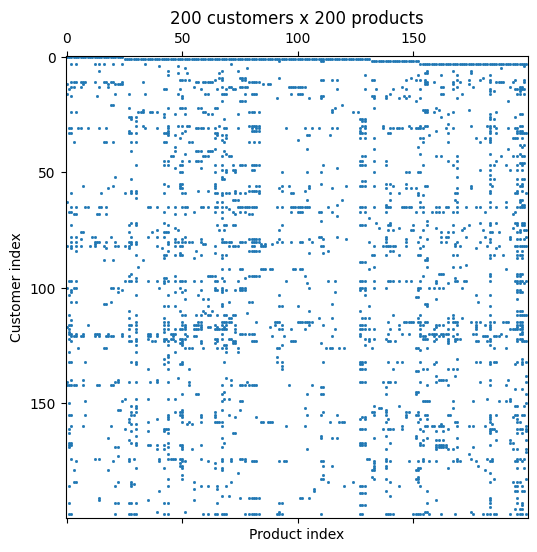

In [21]:
#each dot is a filled cell: a customer (row) bought a product (column)
plt.figure(figsize=(6, 6))
plt.spy(A[:200, :200], markersize=1)
plt.title("200 customers x 200 products")
plt.xlabel("Product index")
plt.ylabel("Customer index")
plt.show()

Output for DE4 section

In [22]:
sp.save_npz("data/processed/A_train.npz", A) # save the sparse matrix in scipy's own format
pd.Series(cust, name="row").rename_axis("Customer ID").to_csv("data/processed/customer_index.csv")  # Customer ID -> row number in A
pd.Series(prod, name="col").rename_axis("StockCode").to_csv("data/processed/product_index.csv")     # StockCode -> column number in A

#### DE5

In [23]:
#matrix report (DE5): size, sparsity and memory, dense vs sparse
n_customers, n_products = A.shape                      # rows = customers, columns = products
total_cells = n_customers * n_products                 # every cell, filled or empty
filled = A.nnz / total_cells                           # share of cells that are not zero

matrix_report = pd.Series({                            # Series = one column of named values
      "Customers (Rows)": n_customers,                   # how many customers
      "Products (Columns)": n_products,                  # how many products
      "Total Cells": total_cells,                        # size if we stored everything
      "Non-Zero Cells": A.nnz,                           # cells that hold a purchase
      "Sparsity %": round((1 - filled) * 100, 2),        # share of empty cells
      "Dense Memory (MB)": round(total_cells * 8 / 1e6, 1),        # 8 bytes for every cell
      "Sparse Memory (MB)": round((A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1e6, 1),  # only what CSR actually stores
}, dtype = object)
matrix_report   


Customers (Rows)          5473
Products (Columns)        3687
Total Cells           20178951
Non-Zero Cells          413927
Sparsity %               97.95
Dense Memory (MB)        161.4
Sparse Memory (MB)         5.0
dtype: object

### ML Tasks

#### ML1

We chose Truncated SVD as our main method because our matrix is 97.95% empty and SVD works directly on the sparse matrix without filling it in, and because one fit gives us both customer factors and product factors (a short list of theme scores for every customer and every product), so we can find similar products for ML3 straight from the product factors. Truncated because we will only keep top k themes which have the biggest values, so the data is compressed from 3,687 columns to k numbers per customer and product

#### ML2


In [24]:
# ML2: Truncated SVD on the sparse matrix (no centring)
t = time.time()
svd = TruncatedSVD(n_components=50, random_state=42).fit(A)
print("fit seconds", time.time() - t)
P_vec = normalize(svd.components_.T) # one row per product, length 1

fit seconds 0.0759439468383789


Since fit takes under 0.2 seconds we can conclude that 'too slow' is not an issue anymore.

In [25]:
results = []                                                       # one entry per k

for k in [10, 20, 50, 100, 200]:
    t = time.time()                                                # start the timer
    svd = TruncatedSVD(n_components=k, random_state=42).fit(A)
    fit_seconds = time.time() - t                                  # stop the timer: fit time only
    A_k = svd.inverse_transform(svd.transform(A))
    error = np.linalg.norm(A.toarray() - A_k) / sp.linalg.norm(A)
    results.append({"k": k, "fit_seconds": round(fit_seconds, 2), "error": round(error, 3)})

results = pd.DataFrame(results)                                    # list -> table
results

,k,fit_seconds,error
0,10,0.03,0.876
1,20,0.04,0.846
2,50,0.07,0.790
3,100,0.14,0.728
4,200,0.29,0.640


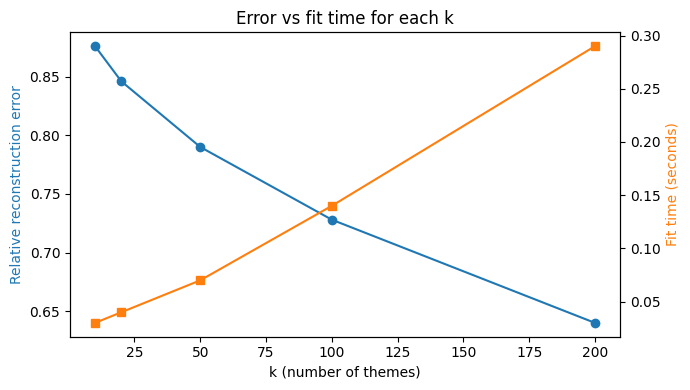

In [26]:
#error vs time tradeoff for each k for more informed decision

fig, ax_error = plt.subplots(figsize=(7, 4))
ax_time = ax_error.twinx()                                          # second y-axis on the right, same k axis

ax_error.plot(results["k"], results["error"], marker="o", color="tab:blue", label="Error (what we lose)")
ax_time.plot(results["k"], results["fit_seconds"], marker="s", color="tab:orange", label="Fit time (seconds)")

ax_error.set_xlabel("k (number of themes)")
ax_error.set_ylabel("Relative reconstruction error", color="tab:blue")
ax_time.set_ylabel("Fit time (seconds)", color="tab:orange")
ax_error.set_title("Error vs fit time for each k")                                     
plt.tight_layout(); plt.show()

Error goes down steadily with no clear flattening. Every extra theme still helps a little overall. Timing for any k stays under 0.3 seconds, which is very good, and we wouldn't consider it a constraint - all k fit fast. So we chose k = 100 as a balance between what we lose (error 0.73) and what we store and we will confirm it with the hit rate in ML4.

#### ML3

In [27]:
#fitting our model
svd_100 = TruncatedSVD(n_components=100, random_state=42).fit(A)
print(svd_100.components_.shape)

(100, 3687)


Next, will measure how much memory the stored customer and product factors take for k = 100, with the goal of showing how much smaller the compressed result is than the full matrix, which answers Sarah's question of how big the result is.

In [28]:
# one row of 100 theme scores per customer (5473 x 100)
customer_factors = svd_100.transform(A)
 # 100 theme scores per product, stored as (100 x 3687)
product_factors = svd_100.components_ 
factors_mb = (customer_factors.nbytes + product_factors.nbytes) / 1e6   # .nbytes = memory used, in bytes
print("Stored factors (k=100):", round(factors_mb, 1), "MB")
print("Full dense matrix:", round(total_cells * 8 / 1e6, 1), "MB")
print("Compression: about", round(total_cells * 8 / 1e6 / factors_mb), "times smaller")

Stored factors (k=100): 7.3 MB
Full dense matrix: 161.4 MB
Compression: about 22 times smaller


We flip to one row per product, then scale each row to length of 1; .T is needed because we need to have one row per product, but components stores themes as rows.

In [29]:
P_vec = normalize(svd_100.components_.T)
print(P_vec.shape)

(3687, 100)


In [30]:
# ML3: 10 products most similar to product j
"""similar takes a product number j and compares that one product with the rest"""
def similar(j, n=10):
    s = P_vec @ P_vec[j] #cosine similarity of product j with every other
    s[j] = -np.inf #exclude product j itself since its the most similar to itself
    return np.argsort(-s)[:n] #column numbers of the n highest scores

Want to test function above on one of the products from our matrix. I'll take 79323P as an example which is PINK CHERRY LIGHTS.

In [31]:
product_codes = list(prod.keys())                                
product_names = train.groupby("StockCode")["Description"].first()  # StockCode -> product name

j = prod["79323P"]                                                 
print("Products similar to:", product_names["79323P"])
for col in similar(j):                                             # 10 most similar columns
    code = product_codes[col]
    print(code, product_names[code])

Products similar to: PINK CHERRY LIGHTS
79323W  WHITE CHERRY LIGHTS
79323LP LIGHT PINK CHERRY LIGHTS
79323GR GREEN CHERRY LIGHTS
79323S  SILVER CHERRY LIGHTS
85042 ANTIQUE LILY FAIRY LIGHTS
79342B BROWN FLOWER LIGHTS
79323G GOLD  CHERRY LIGHTS
85047 WHITE BEADED GARLAND STRING 20LIGHT
20776 ABSTRACT CIRCLES NOTEBOOK
79321 CHILLI LIGHTS


Out of 10 similar items only 20776 Abstract Circles Notebook looks out of place, every other item somehow connected with light so works for our purpose.

In [32]:
#check if works with one customer
i = cust[13085]
customer_row = A[i]
print(customer_row.shape) #expect 1, 3687

#combining the vectors of everything chosen customer has bought into one vector of 100 theme scores
taste = customer_row @ P_vec
print(taste.shape) #expect 1, 100

#score every product
product_scores = taste @ P_vec.T
print(product_scores.shape)

#skip what they already bought, then take top 10 choices
scores = product_scores[0]
bought = customer_row.indices
print("How many products chosen customer already had: ", len(bought))
scores[bought] = -np.inf #set to minus infinity - hide the products
top10 = np.argsort(-scores)[:10]

for top in top10:
    print(product_codes[top], product_names[product_codes[top]])

(1, 3687)
(1, 100)
(1, 3687)
How many products chosen customer already had:  50
22132 RED LOVE HEART SHAPE CUP
22134 LADLE LOVE HEART RED 
22135 LADLE LOVE HEART PINK
22131 FOOD CONTAINER SET 3 LOVE HEART 
84050 PINK HEART SHAPE EGG FRYING PAN
22133 PINK LOVE HEART SHAPE CUP
48194 DOORMAT HEARTS
22752 SET 7 BABUSHKA NESTING BOXES
22365 DOORMAT RESPECTABLE HOUSE
79320  FLAMINGO LIGHTS


Check for one customer succesfully completed, next we will try to make a function out of it.

In [33]:
def recommend(customer_id, n=10):
    i = cust[customer_id]
    customer_row = A[i]
    taste = customer_row @P_vec
    scores = (taste @P_vec.T)[0]
    scores[customer_row.indices] = -np.inf
    return np.argsort(-scores)[:n]

for col in recommend(13085):
      print(product_codes[col], product_names[product_codes[col]]) #test

22132 RED LOVE HEART SHAPE CUP
22134 LADLE LOVE HEART RED 
22135 LADLE LOVE HEART PINK
22131 FOOD CONTAINER SET 3 LOVE HEART 
84050 PINK HEART SHAPE EGG FRYING PAN
22133 PINK LOVE HEART SHAPE CUP
48194 DOORMAT HEARTS
22752 SET 7 BABUSHKA NESTING BOXES
22365 DOORMAT RESPECTABLE HOUSE
79320  FLAMINGO LIGHTS


#### ML4

In [34]:
"""from our test_new rows where we have one row per (customer, product) we want to group those by customers, 
so for each customer we get a set of StockCodes they bought"""

actual = test_new.groupby("Customer ID")["StockCode"].apply(set)
example_id = actual.index[0]          # first test customer
print("Customer #",example_id, "bought these stock codes: \n", actual[example_id])

recommended_codes = set(product_codes[col] for col in recommend(example_id))  
print("\nRecommended:", recommended_codes)
print("Hits:", recommended_codes & actual[example_id])


Customer # 12347 bought these stock codes: 
 {23552, 21636, 21265, 22945, 22561, 23480, 23497, 23503, 23506, 23508, 47580, 22621, '47567B', 23271, 22252, 22131, 23420, 23421, 23422}

Recommended: {'71406C', 71403, '35471A', 20781, '35809B', 35922, 23315, 84306, 20819, 22135}
Hits: set()


In [35]:
t = time.time()                                                     # start timer: the whole "nightly job"
hits = 0                                                            # customers with at least one hit

for customer_id in actual.index:                                    # every test customer
    recommended_codes = set(product_codes[col] for col in recommend(customer_id))
    if recommended_codes & actual[customer_id]:                     # non-empty set = at least one hit
        hits += 1

job_seconds = time.time() - t
hit_rate = hits / len(actual)
print("Hit rate at 10 (SVD, k=100):", round(hit_rate * 100, 1), "%")
print("Time to recommend for", len(actual), "customers:", round(job_seconds, 1), "seconds")

Hit rate at 10 (SVD, k=100): 23.4 %
Time to recommend for 1930 customers: 0.3 seconds


Almost 1 in 4 customers got at least one correct product in their top 10. Now we need to see if our reccomendation is better then just top 10 of most wanted products.

In [36]:
best_sellers = list(customers_per_product.index)                    # all products, most customers first
owned = train.groupby("Customer ID")["StockCode"].apply(set)        # customer -> everything they bought in training

baseline_hits = 0
for customer_id in actual.index:
    top10_new = [p for p in best_sellers if p not in owned[customer_id]][:10]   # best sellers they don't have yet, first 10
    if set(top10_new) & actual[customer_id]:
        baseline_hits += 1

baseline_rate = baseline_hits / len(actual)
print("Hit rate at 10 (best-seller baseline):", round(baseline_rate * 100, 1), "%")

Hit rate at 10 (best-seller baseline): 26.6 %


So our baseline of 23.4% does not beat baseline of 26.6% for best-sellers. I'll test reccomendations with different k to see if there is a better result.

In [37]:
hit_results = []

for k in [10, 20, 50, 100, 200]:
    svd_k = TruncatedSVD(n_components=k, random_state=42).fit(A)
    P_vec = normalize(svd_k.components_.T)                  # recommend() uses P_vec, so this switches the model to k themes
    hits = 0
    for customer_id in actual.index:
        recommended_codes = set(product_codes[col] for col in recommend(customer_id))
        if recommended_codes & actual[customer_id]: hits += 1
    hit_results.append({"k": k, "hit_rate_%": round(hits / len(actual) * 100, 1)})

P_vec = normalize(svd_100.components_.T)                   
pd.DataFrame(hit_results)

,k,hit_rate_%
0,10,14.0
1,20,18.0
2,50,20.7
3,100,23.4
4,200,21.2


Unfortunately, none of the K gives us better result then best-selling baseline. However, we can see that at least the chosen k= 100 gives out better results then others - thats a cnfirmation of good choice.
We can try to add a small bonus to each product score based on how many customers bought it to see if results will improve

In [38]:
#-----How popular is each product--------
#A>0 turn every cell into True (bought) or False (not bought); 
#sum(axis-0) count True going down each column = how many customers bought the product
#np.asarray.ravel() the count comes out as 1 row table but we flatten it into plain list
popularity = np.asarray((A > 0).sum(axis=0)).ravel()
popularity = popularity / popularity.max()    #divide by the biggest count, most popular product gets 1, the rest is in range of 0 to 1 

#-----Reccomend with popularity bonus----
def recommend_pop(customer_id, w, n=10):
    customer_row = A[cust[customer_id]] #find this customers row and what they bought
    taste = normalize(customer_row @ P_vec)  #mixing their products into one taste, then making length 1 so taste scores stay between -1 and 1
    scores = (1 - w) * (taste @ P_vec.T)[0] + w * popularity 
    scores[customer_row.indices] = -np.inf #lowest score for the things they already bought
    return np.argsort(-scores)[:n] # sort and return

pop_results = []

for w in [0, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]:                    # mix: 0 = pure taste, 1 = pure popularity
    hits = 0
    for customer_id in actual.index:
        recommended_codes = set(product_codes[col] for col in recommend_pop(customer_id, w))
        if recommended_codes & actual[customer_id]: hits += 1
    pop_results.append({"w": w, "hit_rate_%": round(hits / len(actual) * 100, 1)})

pd.DataFrame(pop_results)


,w,hit_rate_%
0,0.0,23.4
1,0.1,25.2
2,0.2,26.3
3,0.3,29.6
4,0.5,33.1
5,0.7,28.1
6,1.0,26.6


We get much better results at w = 0.5, where we have a hit rate of 33.1%, which beats the baseline of best-selling items (26.6%).We picked w = 0.5 by looking at the test results, so 33.1% may be a little too good. A truly fair test would choose w on different data.

In [39]:
pop_table = pd.DataFrame(pop_results).set_index("w") 

ml4_results = pd.DataFrame({
      "Method": ["Best-seller baseline", "SVD k=100", "SVD k=100 + popularity (w=0.5)"],
      "Hit rate at 10 (%)": [round(baseline_rate * 100, 1),     # from the baseline cell
                             round(hit_rate * 100, 1),          # from the nightly-job cell
                             pop_table.loc[0.5, "hit_rate_%"]], # from the popularity table
  })
ml4_results

,Method,Hit rate at 10 (%)
0,Best-seller baseline,26.6
1,SVD k=100,23.4
2,SVD k=100 + popularity (w=0.5),33.1


In [40]:
print("Nightly job: recommendations for", len(actual), "customers in", round(job_seconds, 1),
  "seconds")

Nightly job: recommendations for 1930 customers in 0.3 seconds


#### ML5

In [41]:
def fit_and_measure(model):
    tracemalloc.start()                                  #start watching memory
    t = time.time()                                      #start the timer
    model.fit(A)                                         #fit on our training matrix
    seconds = time.time() - t                            #stop the timer
    peak_mb = tracemalloc.get_traced_memory()[1] / 1e6   #[1] = highest memory used during the fit, in MB
    tracemalloc.stop()                                   #stop watching
    return model, seconds, peak_mb

svd_cmp, svd_seconds, svd_peak = fit_and_measure(TruncatedSVD(n_components=100, random_state=42))
pca_cmp, pca_seconds, pca_peak = fit_and_measure(PCA(n_components=100, svd_solver="arpack", random_state=42))

print("SVD:", round(svd_seconds, 2), "s,", round(svd_peak, 1), "MB peak")
print("PCA:", round(pca_seconds, 2), "s,", round(pca_peak, 1), "MB peak") # did not use PCA but measuring according to requirments

SVD: 0.16 s, 17.8 MB peak
PCA: 0.2 s, 16.7 MB peak


Both methods fit in about 0.2 seconds and use a similar peak memory (17.8 MB for SVD and 16.7 MB for PCA). We expected PCA to be heavier because centring fills in the zeros, but the arpack solver centres the matrix implicitly without building a dense copy, so at our size there is almost no difference in speed or memory. So if, for example, the catalogue grew to hundreds of thousands of products, this difference could start to matter.

In [42]:
svd_var = svd_cmp.explained_variance_ratio_.sum()        # share of the variation SVD's 100 themes capture
pca_var = pca_cmp.explained_variance_ratio_.sum()        # same for PCA (PCA's own language)

svd_size = (svd_cmp.transform(A).nbytes + svd_cmp.components_.nbytes) / 1e6   # customer + product factors, MB
pca_size = (pca_cmp.transform(A).nbytes + pca_cmp.components_.nbytes) / 1e6

print("Variance explained - SVD:", round(svd_var * 100, 1), "% | PCA:", round(pca_var * 100, 1), "%")
print("Stored factors - SVD:", round(svd_size, 1), "MB | PCA:", round(pca_size, 1), "MB")

Variance explained - SVD: 44.6 % | PCA: 44.8 %
Stored factors - SVD: 7.3 MB | PCA: 7.3 MB


Both methods keep almost the same share of the information with 100 themes (44.6% of the variance for SVD and 44.8% for PCA), and both store the same 7.3 MB of factors, because each keeps 100 numbers per customer and per product. So on compression the two methods are practically equal, and the real difference has to show up in what each one is used for, which we test next with the hit rate

In [43]:
"""
Test PCA the same way we tested SVD by giviing recommend() PCA's product vectors,
count how many test customers get at least one real purchase in their top 10,
then switch back to our SVD model and compare the two hit rates.
"""
# PCA's hit rate
P_vec = normalize(pca_cmp.components_.T)                 # use PCA's product vectors in recommend()
hits = 0
for customer_id in actual.index:
    recommended_codes = set(product_codes[col] for col in recommend(customer_id))
    if recommended_codes & actual[customer_id]: hits += 1
pca_hit_rate = hits / len(actual)

P_vec = normalize(svd_100.components_.T)
print("Hit rate at 10 - PCA:", round(pca_hit_rate * 100, 1), "% | SVD:", round(hit_rate * 100, 1), "%")
print("SVD found a hit for", round((hit_rate - pca_hit_rate) * len(actual)),
      "more customers than PCA, out of", len(actual), "test customers")

Hit rate at 10 - PCA: 22.7 % | SVD: 23.4 %
SVD found a hit for 13 more customers than PCA, out of 1930 test customers


SVD has a slightly higher hit rate then PCA, so we did a right choice by choosing to go with SVD, although difference is small.

In [44]:
"""
Look at theme 1 of each model: what share of products have a positive weight,
and which 5 products have the biggest weight, to describe what theme 1 means in words.
"""
for name, model in [("SVD", svd_cmp), ("PCA", pca_cmp)]:
    comp1 = model.components_[0]                                   # weight of every product in theme 1
    print(name, "- share of products with positive weight:", round((comp1 > 0).mean() * 100, 1), "%")
    for col in np.argsort(-np.abs(comp1))[:5]:                     # 5 products with the biggest weight (+ or -)
        print("   ", round(comp1[col], 3), product_names[product_codes[col]])

SVD - share of products with positive weight: 100.0 %
    0.13 PACK OF 72 RETRO SPOT CAKE CASES
    0.122 WHITE HANGING HEART T-LIGHT HOLDER
    0.108 JUMBO BAG RED WHITE SPOTTY 
    0.1 LUNCH BAG RED SPOTTY
    0.091 60 TEATIME FAIRY CAKE CASES
PCA - share of products with positive weight: 99.8 %
    0.123 PACK OF 72 RETRO SPOT CAKE CASES
    0.106 JUMBO BAG RED WHITE SPOTTY 
    0.103 LUNCH BAG RED SPOTTY
    0.094 WHITE HANGING HEART T-LIGHT HOLDER
    0.087 60 TEATIME FAIRY CAKE CASES


In both models almost every product has a positive weight in theme 1 (100% for SVD and 99.8% for PCA), and the products with the biggest weights are our best sellers (retro spot cake cases, the white hanging heart, red spotty bags). So theme 1 does not describe a style of product, it describes how much a customer buys overall, especially of the most popular items. We expected this for SVD, and PCA's theme 1 turned out almost the same, because the biggest difference between customers is how much they buy

In [45]:
#Fill in the brief's PCA vs SVD comparison table (ML5), using only numbers our notebook already computed.

svd_error_100 = results.set_index("k").loc[100, "error"]     # SVD's reconstruction error at k=100, from ML2

comparison = pd.DataFrame({
    "PCA": [100, round(pca_seconds, 2), round(pca_peak, 1), round(pca_size, 1),
            f"{pca_var:.1%} variance explained",
            f"{pca_hit_rate:.1%}", f"{baseline_rate:.1%}",
            "Overall buying volume, mostly of best sellers"],
    "Truncated SVD": [100, round(svd_seconds, 2), round(svd_peak, 1), round(svd_size, 1),
            f"{svd_var:.1%} variance explained (error {svd_error_100})",
            f"{hit_rate:.1%}", f"{baseline_rate:.1%}",
            "Overall buying volume, mostly of best sellers"],
}, index=["k", "Fit time (sec)", "Peak memory during fit (MB)",
          "Size of stored factors (MB)", "Variance explained / Error",
          "Hit rate @ 10", "Best-seller baseline",
          "Component 1 representation in words"])
comparison

,PCA,Truncated SVD
k,100,100
Fit time (sec),0.2,0.16
Peak memory during fit (MB),16.7,17.8
Size of stored factors (MB),7.3,7.3
Variance explained / Error,44.8% variance explained,44.6% variance explained (error 0.728)
Hit rate @ 10,22.7%,23.4%
Best-seller baseline,26.6%,26.6%
Component 1 representation in words,"Overall buying volume, mostly of best sellers","Overall buying volume, mostly of best sellers"


We compared PCA and SVD with the same k = 100 on the same matrix, and on cost they turned out almost equal (both fit in about 0.2 seconds, use similar peak memory of 16.7 and 17.8 MB, store the same 7.3 MB of factors and keep about 45% of the variance). In both models the first theme means how much a customer buys overall, so the only real difference is the hit rate, where SVD is slightly ahead (23.4% against 22.7%). So if, for example, our catalogue grew a lot bigger, SVD working directly on the sparse matrix would matter even more. Neither method beats the best-seller baseline (26.6%) on its own, which is why we added the popularity bonus in ML4.

Leaving SVD as our main method.

#### ML6

Goal: place every customer on 2 components, split them in 3-6 groups using k-means, and name each group from its top product and countries.

Issue: theme 1 is just "how much they buy"

Plan:
1. Scale each customer to length of 1 by normalizing, so big and small shops with the same taste land in the same spot
2. Use themes 2 and 3 for the map instead of 1 and 2, because theme 1 is solely based on volume and we need taste.